In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
df=pd.read_csv(r"mushrooms.csv")

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8124 entries, 0 to 8123
Data columns (total 23 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   class                     8124 non-null   object
 1   cap-shape                 8124 non-null   object
 2   cap-surface               8124 non-null   object
 3   cap-color                 8124 non-null   object
 4   bruises                   8124 non-null   object
 5   odor                      8124 non-null   object
 6   gill-attachment           8124 non-null   object
 7   gill-spacing              8124 non-null   object
 8   gill-size                 8124 non-null   object
 9   gill-color                8124 non-null   object
 10  stalk-shape               8124 non-null   object
 11  stalk-root                8124 non-null   object
 12  stalk-surface-above-ring  8124 non-null   object
 13  stalk-surface-below-ring  8124 non-null   object
 14  stalk-color-above-ring  

In [4]:
df.columns

Index(['class', 'cap-shape', 'cap-surface', 'cap-color', 'bruises', 'odor',
       'gill-attachment', 'gill-spacing', 'gill-size', 'gill-color',
       'stalk-shape', 'stalk-root', 'stalk-surface-above-ring',
       'stalk-surface-below-ring', 'stalk-color-above-ring',
       'stalk-color-below-ring', 'veil-type', 'veil-color', 'ring-number',
       'ring-type', 'spore-print-color', 'population', 'habitat'],
      dtype='object')

In [5]:
y=df['class']

In [6]:
x=df[['cap-shape', 'cap-surface', 'cap-color', 'bruises', 'odor',
       'gill-attachment', 'gill-spacing', 'gill-size', 'gill-color',
       'stalk-shape', 'stalk-root', 'stalk-surface-above-ring',
       'stalk-surface-below-ring', 'stalk-color-above-ring',
       'stalk-color-below-ring', 'veil-type', 'veil-color', 'ring-number',
       'ring-type', 'spore-print-color', 'population', 'habitat']]

In [7]:
from sklearn.preprocessing import LabelEncoder
l = LabelEncoder()
y=l.fit_transform(y)
print(y)

[1 0 0 ... 0 1 0]


In [8]:
x.shape, y.shape

((8124, 22), (8124,))

In [9]:
for i in x.columns:
    if x[i].dtype == 'object':
        x[i] = l.fit_transform(x[i])

C:\Users\smart\AppData\Local\Temp\ipykernel_26176\1672672217.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  x[i] = l.fit_transform(x[i])
C:\Users\smart\AppData\Local\Temp\ipykernel_26176\1672672217.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  x[i] = l.fit_transform(x[i])
C:\Users\smart\AppData\Local\Temp\ipykernel_26176\1672672217.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the cave

In [10]:
print(x.isnull().sum())
x = x.fillna(x.mean())

cap-shape                   0
cap-surface                 0
cap-color                   0
bruises                     0
odor                        0
gill-attachment             0
gill-spacing                0
gill-size                   0
gill-color                  0
stalk-shape                 0
stalk-root                  0
stalk-surface-above-ring    0
stalk-surface-below-ring    0
stalk-color-above-ring      0
stalk-color-below-ring      0
veil-type                   0
veil-color                  0
ring-number                 0
ring-type                   0
spore-print-color           0
population                  0
habitat                     0
dtype: int64


C:\Users\smart\AppData\Local\Temp\ipykernel_26176\131231279.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='class', data=df, palette='viridis')


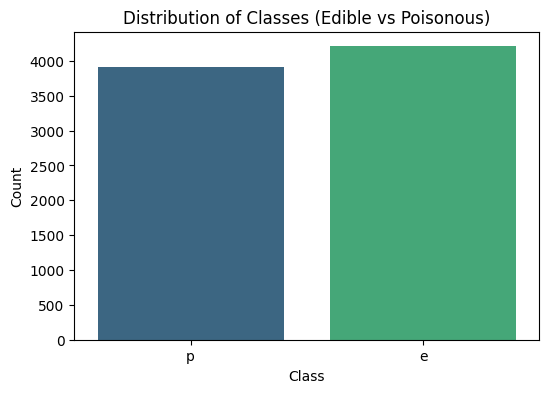

In [11]:
import seaborn as sns
import matplotlib.pyplot as plt

# Checking the distribution of the target variable
plt.figure(figsize=(6, 4))
sns.countplot(x='class', data=df, palette='viridis')
plt.title('Distribution of Classes (Edible vs Poisonous)')
plt.xlabel('Class')
plt.ylabel('Count')
plt.show()

In [12]:
x.corr

<bound method DataFrame.corr of       cap-shape  cap-surface  cap-color  bruises  odor  gill-attachment  \
0             5            2          4        1     6                1   
1             5            2          9        1     0                1   
2             0            2          8        1     3                1   
3             5            3          8        1     6                1   
4             5            2          3        0     5                1   
...         ...          ...        ...      ...   ...              ...   
8119          3            2          4        0     5                0   
8120          5            2          4        0     5                0   
8121          2            2          4        0     5                0   
8122          3            3          4        0     8                1   
8123          5            2          4        0     5                0   

      gill-spacing  gill-size  gill-color  stalk-shape  ...  \
0   

In [13]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report,accuracy_score,confusion_matrix

In [14]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.3,random_state=42)

In [15]:
x_train.shape,x_test.shape,y_train.shape,y_test.shape

((5686, 22), (2438, 22), (5686,), (2438,))

In [16]:
from sklearn.ensemble import RandomForestClassifier
model=RandomForestClassifier(n_estimators=100, max_depth=5, random_state=42)

In [17]:
model.fit(x_train, y_train)
y_pred=model.predict(x_test)
y_pred_proba = model.predict_proba(x_test)[:,-1]

In [18]:
c=classification_report(y_test,y_pred)
print("Classification Report")
print(c)

Classification Report
              precision    recall  f1-score   support

           0       0.98      1.00      0.99      1257
           1       1.00      0.98      0.99      1181

    accuracy                           0.99      2438
   macro avg       0.99      0.99      0.99      2438
weighted avg       0.99      0.99      0.99      2438



In [19]:
print("Accuracy Score")

a=accuracy_score(y_test,y_pred)*100
print(a)

Accuracy Score
98.93355209187858


In [20]:
# Checking the R² score for the training data
train_score = model.score(x_train, y_train)
print(f"Training R² score: {train_score:.4f}")

# Checking the R² score for the test data
test_score = model.score(x_test, y_test)
print(f"Testing R² score: {test_score:.4f}")

Training R² score: 0.9909
Testing R² score: 0.9893


In [21]:
import pickle

with open('model.pkl', 'wb') as file:
    pickle.dump(model, file)

print("Model saved as 'logistic_model.pkl'")

Model saved as 'logistic_model.pkl'


In [22]:
with open('label_encoder.pkl', 'wb') as encoder_file:
    pickle.dump(l, encoder_file)

print("Model and LabelEncoder saved successfully.")

Model and LabelEncoder saved successfully.


In [23]:
import logging
import streamlit as st
import pandas as pd
import numpy as np
from sklearn.preprocessing import LabelEncoder
import pickle

# Configure logging
logging.basicConfig(
    level=logging.INFO,
    format='%(asctime)s - %(levelname)s - %(message)s'
)

# Human-readable full form mappings for mushroom features
FEATURE_VALUE_MAPPINGS = {
    'cap-shape': {
        'b': 'Bell', 'c': 'Conical', 'x': 'Convex', 
        'f': 'Flat', 'k': 'Knobbed', 's': 'Sunken'
    },
    'cap-surface': {
        'f': 'Fibrous', 'g': 'Grooves', 'y': 'Scaly', 's': 'Smooth'
    },
    'cap-color': {
        'n': 'Brown', 'b': 'Buff', 'c': 'Cinnamon', 'g': 'Gray', 
        'r': 'Green', 'p': 'Pink', 'u': 'Purple', 'e': 'Red', 
        'w': 'White', 'y': 'Yellow'
    },
    'bruises': {
        't': 'Bruises', 'f': 'No Bruises'
    },
    'odor': {
        'a': 'Almond', 'l': 'Anise', 'c': 'Creosote', 'y': 'Fishy', 
        'f': 'Foul', 'm': 'Musty', 'n': 'None (No Odor)', 
        'p': 'Pungent', 's': 'Spicy'
    },
    'gill-attachment': {
        'a': 'Attached', 'f': 'Free'
    },
    'gill-spacing': {
        'c': 'Close', 'w': 'Crowded'
    },
    'gill-size': {
        'b': 'Broad', 'n': 'Narrow'
    },
    'gill-color': {
        'k': 'Black', 'n': 'Brown', 'b': 'Buff', 'h': 'Chocolate', 
        'g': 'Gray', 'r': 'Green', 'o': 'Orange', 'p': 'Pink', 
        'u': 'Purple', 'e': 'Red', 'w': 'White', 'y': 'Yellow'
    },
    'stalk-shape': {
        'e': 'Enlarging', 't': 'Tapering'
    },
    'stalk-root': {
        'b': 'Bulbous', 'c': 'Club', 'e': 'Equal', 
        'r': 'Rooted', '?': 'Missing / Unknown'
    },
    'stalk-surface-above-ring': {
        'f': 'Fibrous', 'y': 'Scaly', 'k': 'Silky', 's': 'Smooth'
    },
    'stalk-surface-below-ring': {
        'f': 'Fibrous', 'y': 'Scaly', 'k': 'Silky', 's': 'Smooth'
    },
    'stalk-color-above-ring': {
        'n': 'Brown', 'b': 'Buff', 'c': 'Cinnamon', 'g': 'Gray', 
        'o': 'Orange', 'p': 'Pink', 'e': 'Red', 'w': 'White', 'y': 'Yellow'
    },
    'stalk-color-below-ring': {
        'n': 'Brown', 'b': 'Buff', 'c': 'Cinnamon', 'g': 'Gray', 
        'o': 'Orange', 'p': 'Pink', 'e': 'Red', 'w': 'White', 'y': 'Yellow'
    },
    'veil-type': {
        'p': 'Partial'
    },
    'veil-color': {
        'n': 'Brown', 'o': 'Orange', 'w': 'White', 'y': 'Yellow'
    },
    'ring-number': {
        'n': 'None', 'o': 'One', 't': 'Two'
    },
    'ring-type': {
        'e': 'Evanescent', 'f': 'Flaring', 'l': 'Large', 
        'n': 'None', 'p': 'Pendant'
    },
    'spore-print-color': {
        'k': 'Black', 'n': 'Brown', 'b': 'Buff', 'h': 'Chocolate', 
        'r': 'Green', 'o': 'Orange', 'u': 'Purple', 'w': 'White', 'y': 'Yellow'
    },
    'population': {
        'a': 'Abundant', 'c': 'Clustered', 'n': 'Numerous', 
        's': 'Scattered', 'v': 'Several', 'y': 'Solitary'
    },
    'habitat': {
        'd': 'Woods', 'g': 'Grasses', 'l': 'Leaves', 'm': 'Meadows', 
        'p': 'Paths', 'u': 'Urban', 'w': 'Waste'
    }
}

def format_feature_option(feature, code):
    full_name = FEATURE_VALUE_MAPPINGS.get(feature, {}).get(code)
    if full_name:
        return f"{full_name} ({code})"
    return str(code)

# Load the trained model and LabelEncoder
try:
    with open('model.pkl', 'rb') as model_file:
        model = pickle.load(model_file)
    logging.info("Model loaded successfully.")
except Exception as e:
    logging.error(f"Error loading model: {e}")

try:
    with open('label_encoder.pkl', 'rb') as encoder_file:
        label_encoder = pickle.load(encoder_file)
    logging.info("LabelEncoder loaded successfully.")
except Exception as e:
    logging.error(f"Error loading LabelEncoder: {e}")

# Load the dataset for feature options
try:
    df = pd.read_csv('mushrooms.csv')
    logging.info("Dataset loaded successfully.")
except Exception as e:
    logging.error(f"Error loading dataset: {e}")

# All features used in training
all_features = [
    'cap-shape', 'cap-surface', 'cap-color', 'bruises', 'odor', 'gill-attachment',
    'gill-spacing', 'gill-size', 'gill-color', 'stalk-shape', 'stalk-root',
    'stalk-surface-above-ring', 'stalk-surface-below-ring', 'stalk-color-above-ring',
    'stalk-color-below-ring', 'veil-type', 'veil-color', 'ring-number', 'ring-type',
    'spore-print-color', 'population', 'habitat'
]

# Selected features for classification
selected_features = [
    'bruises', 'gill-size', 'gill-spacing', 'gill-color',
    'stalk-surface-below-ring', 'veil-color', 'ring-type', 'population', 'habitat',
]

# Streamlit Interface
st.title('Mushroom Classification')

st.write("Provide values for the following features:")

# Create input fields for selected features
user_inputs = {}
for feature in selected_features:
    user_inputs[feature] = st.selectbox(
        feature,
        options=df[feature].unique(),
        format_func=lambda val, f=feature: format_feature_option(f, val)
    )

# Create a complete input data array with default values
input_data = []
for feature in all_features:
    if feature in selected_features:
        if user_inputs[feature] in label_encoder.classes_:
            input_data.append(label_encoder.transform([user_inputs[feature]])[0])
        else:
            # Handle unseen labels
            logging.warning(f"Unseen label encountered: {user_inputs[feature]} for feature {feature}")
            input_data.append(0)  # Default value for unseen labels
    else:
        # Use default values for other features
        input_data.append(0)  # Default value

# Convert the inputs into a DataFrame for prediction
input_df = pd.DataFrame([input_data], columns=all_features)

# Prediction button
if st.button('Classify'):
    try:
        prediction = model.predict(input_df)[0]
        prediction_prob = model.predict_proba(input_df)[0]  # Get probabilities for both classes
        logging.info("Prediction made successfully.")
    except Exception as e:
        logging.error(f"Error during prediction: {e}")
        st.error("An error occurred during prediction. Please check the logs for more details.")
        prediction, prediction_prob = None, None

    if prediction is not None:
        # Extract probabilities for edible and poisonous
        edible_prob = prediction_prob[0]  # Probability for edible (class 0)
        poisonous_prob = prediction_prob[1]  # Probability for poisonous (class 1)

        # Display probabilities and result
        if prediction == 1:  # Poisonous
            st.error(f"Prediction: Poisonous (Probability: {poisonous_prob:.2%})")
            st.warning("Warning! This mushroom is highly poisonous. Avoid consumption!")
        elif prediction == 0:  # Edible
            st.success(f"Prediction: Edible (Probability: {edible_prob:.2%})")
            st.info("This mushroom is safe to eat. Enjoy!")

        # Show detailed probabilities
        st.write("Prediction Probabilities:")
        st.write(f"Edible: {edible_prob:.2%}")
        st.write(f"Poisonous: {poisonous_prob:.2%}")

2026-11-23 22:28:24.864 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-23 22:28:25.275 
  command:

    streamlit run C:\Users\smart\AppData\Roaming\Python\Python312\site-packages\ipykernel_launcher.py [ARGUMENTS]
2026-11-23 22:28:25.276 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-23 22:28:25.276 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-23 22:28:25.277 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-23 22:28:25.279 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-23 22:28:25.279 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-23 22:28:25.281 Thre